In [1]:
import sys
sys.path.insert(0, "..")  # so "utils" (in the project root) can be imported from src/

from utils.modelling import *
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

In [2]:
Xtrain, ytrain, Xval, yval, Xtest, ytest = load_train_val_test('../data/processed/dataset.csv')

In [3]:
GAMMAS = [0, 0.25, 0.5, 0.75]
weights = make_class_weights(ytrain)

def make_random_forest_grid(model="A"):
    return RandomizedSearchCV(
        make_pipeline(
            make_preprocessor(model=model),
            RandomForestClassifier(n_estimators=100, random_state=67)
        ),
        cv=5,
        param_distributions={
            "randomforestclassifier__max_depth": [10, 20, None],
            "randomforestclassifier__min_samples_leaf": [1, 10, 50],
            "randomforestclassifier__max_features": ["sqrt", 0.3],
            "randomforestclassifier__class_weight": [weights(g) for g in GAMMAS],
        },
        n_iter=20, # try 20 random combinations instead of all 72
        random_state=67, # same 20 combinations every run
        scoring="f1_macro",
        n_jobs=-1 # use all cores
    )

forest_grid_A = make_random_forest_grid(model="A").fit(Xtrain, ytrain)
forest_model_tuned_A = forest_grid_A.best_estimator_
best_forest_params_A = forest_grid_A.best_params_
print(best_forest_params_A)
print(f"best CV macro F1: {forest_grid_A.best_score_:.4f}")

{'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 0.3, 'randomforestclassifier__max_depth': None, 'randomforestclassifier__class_weight': {0: np.float64(1.0), 1: np.float64(6.545301885466249), 2: np.float64(9.05123357102088)}}
best CV macro F1: 0.4962


In [4]:
forest_val_A = evaluate_model(forest_model_tuned_A, Xval, yval, "Random Forest A - VAL")

                 precision    recall  f1-score   support

           None       0.98      0.98      0.98     23976
          Minor       0.21      0.16      0.18       560
Subst/Destroyed       0.27      0.40      0.32       293

       accuracy                           0.95     24829
      macro avg       0.49      0.51      0.49     24829
   weighted avg       0.95      0.95      0.95     24829
 Model: Random Forest A - VAL
F1 Macro: 0.4946
Balanced Accuracy: 0.5105
Accuracy: 0.9532
Recall: [0.9785619  0.15714286 0.39590444]
Confusion matrix (rows = true, columns = predicted):
[[23462   278   236]
 [  402    88    70]
 [  131    46   116]]


In [5]:
forest_grid_B = make_random_forest_grid(model="B").fit(Xtrain, ytrain)
forest_model_tuned_B = forest_grid_B.best_estimator_
print(forest_grid_B.best_params_)

{'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 0.3, 'randomforestclassifier__max_depth': None, 'randomforestclassifier__class_weight': {0: np.float64(1.0), 1: np.float64(6.545301885466249), 2: np.float64(9.05123357102088)}}


In [6]:
forest_val_B = evaluate_model(forest_model_tuned_B, Xval, yval, "Random Forest B - VAL")

                 precision    recall  f1-score   support

           None       0.98      0.98      0.98     23976
          Minor       0.28      0.26      0.27       560
Subst/Destroyed       0.31      0.49      0.38       293

       accuracy                           0.95     24829
      macro avg       0.52      0.58      0.54     24829
   weighted avg       0.96      0.95      0.96     24829
 Model: Random Forest B - VAL
F1 Macro: 0.5425
Balanced Accuracy: 0.5761
Accuracy: 0.9542
Recall: [0.97605939 0.26071429 0.49146758]
Confusion matrix (rows = true, columns = predicted):
[[23402   328   246]
 [  335   146    79]
 [  105    44   144]]


In [7]:
forest_cv = [cv_summary(forest_grid_A, "Random Forest A"), cv_summary(forest_grid_B, "Random Forest B")]

Random Forest A: CV macro F1 = 0.4962 +/- 0.0084
Random Forest B: CV macro F1 = 0.5569 +/- 0.0123


In [8]:
forest_test_A = evaluate_model(forest_model_tuned_A, Xtest, ytest, "Random Forest A - TEST")

                 precision    recall  f1-score   support

           None       0.98      0.98      0.98     23976
          Minor       0.26      0.20      0.23       560
Subst/Destroyed       0.29      0.42      0.34       293

       accuracy                           0.95     24829
      macro avg       0.51      0.54      0.52     24829
   weighted avg       0.95      0.95      0.95     24829
 Model: Random Forest A - TEST
F1 Macro: 0.5161
Balanced Accuracy: 0.5350
Accuracy: 0.9543
Recall: [0.97835335 0.20357143 0.42320819]
Confusion matrix (rows = true, columns = predicted):
[[23457   287   232]
 [  370   114    76]
 [  128    41   124]]


In [9]:
forest_test_B = evaluate_model(forest_model_tuned_B, Xtest, ytest, "Random Forest B - TEST")

                 precision    recall  f1-score   support

           None       0.98      0.98      0.98     23976
          Minor       0.31      0.32      0.31       560
Subst/Destroyed       0.32      0.51      0.39       293

       accuracy                           0.95     24829
      macro avg       0.54      0.60      0.56     24829
   weighted avg       0.96      0.95      0.96     24829
 Model: Random Forest B - TEST
F1 Macro: 0.5616
Balanced Accuracy: 0.6016
Accuracy: 0.9549
Recall: [0.97514181 0.31785714 0.51194539]
Confusion matrix (rows = true, columns = predicted):
[[23380   355   241]
 [  299   178    83]
 [  104    39   150]]


In [10]:
results = results_table([forest_val_A, forest_val_B, forest_test_A, forest_test_B])
results.to_csv("../results/random_forest.csv", index=False)
pd.DataFrame(forest_cv).to_csv("../results/random_forest_cv.csv", index=False)
results

,model,f1_macro,bal_acc,accuracy,precision_None,precision_Minor,precision_Subst/Destroyed,recall_None,recall_Minor,recall_Subst/Destroyed,f1_None,f1_Minor,f1_Subst/Destroyed
0,Random Forest A - VAL,0.494573,0.510536,0.953160,0.977787,0.213592,0.274882,0.978562,0.157143,0.395904,0.978174,0.181070,0.324476
1,Random Forest B - VAL,0.542540,0.576080,0.954207,0.981545,0.281853,0.307036,0.976059,0.260714,0.491468,0.978795,0.270872,0.377953
2,Random Forest A - TEST,0.516132,0.535044,0.954328,0.979211,0.257919,0.287037,0.978353,0.203571,0.423208,0.978782,0.227545,0.342069
3,Random Forest B - TEST,0.561568,0.601648,0.954851,0.983055,0.311189,0.316456,0.975142,0.317857,0.511945,0.979082,0.314488,0.391134


## plots

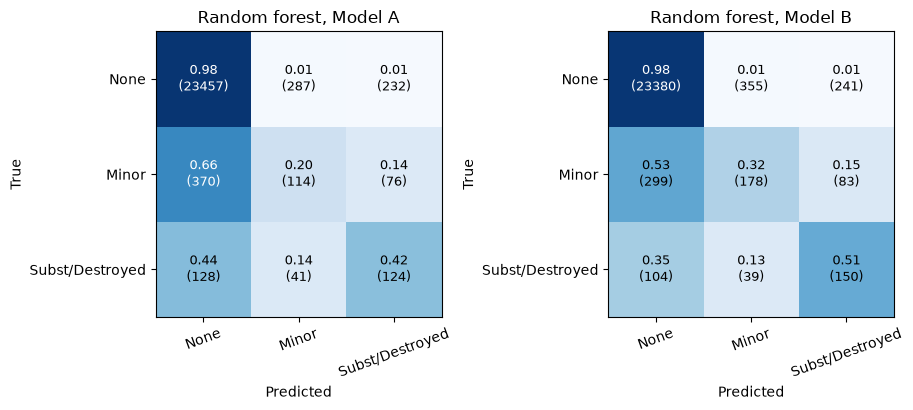

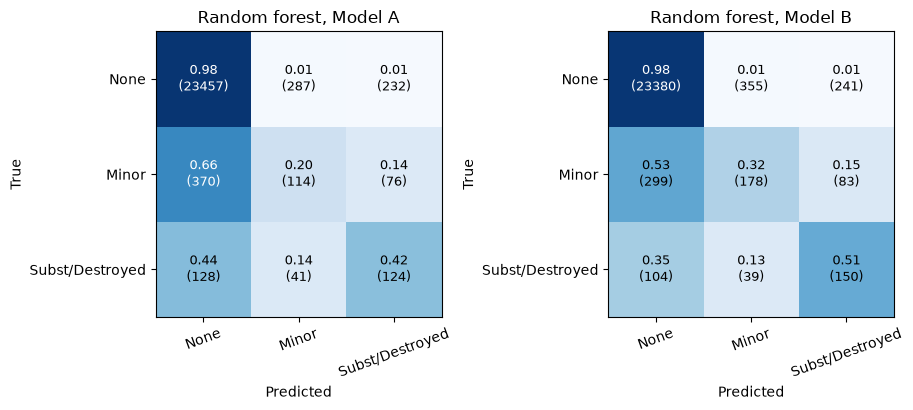

In [11]:
plot_confusion_matrices({"Random forest, Model A": forest_model_tuned_A, "Random forest, Model B": forest_model_tuned_B}, Xtest, ytest, "../plots/cm_random_forest.png")